# Clinical Transformer for Survival - Token por Visita

Notebook hermano de `grud_student_extension.ipynb`. Aqui construimos un
**Transformer Encoder** que predice riesgo de cancer de pulmon a 5 anos a
partir de secuencias longitudinales irregulares de laboratorio.

A diferencia del paper STraTS original - donde cada *triple* (lab, valor, tiempo)
es un token - aqui **cada visita es un token** que fusiona:

1. los valores de los 23 labs medidos en esa visita,
2. la mascara de observacion (que se midio - clave porque los labs ausentes son 0),
3. la **codificacion continua del tiempo** (Time2Vec / STraTS) sobre los anos
   transcurridos desde la edad de entrada a la cohorte (posicion absoluta de la visita),
4. (opcional) el embedding ICD-10 de los diagnosticos registrados en esa visita
   (en el `build_sequences.py` ya se mergean labs + condiciones a un mismo `times[i]`),
5. la covariable estatica `sex_male` (proyectada y broadcasteada a todas las visitas).

La salida se optimiza con la **perdida parcial de Cox** reutilizando los modulos
de `workflow/scripts/` ya implementados para GRU-D (`dataset`, `engine`, `loss`,
`eval`, `model.TimeAwareGRUD` para comparativa).

**Compatibilidad con GRU-D:** el modelo expone la misma firma y el mismo return
que `TimeAwareGRUD`, por lo que `run_raw_loss_epoch_icd`, `collect_raw_outputs`
y `cox_ph_loss` se importan **sin modificarlos** - comparativa justa.

> Che et al. (2018) GRU-D y Tipirneni et al. (2022) STraTS - *Self-attention for*
> *irregularly sampled time series*.
> https://doi.org/10.1038/s41598-018-24271-9
> https://arxiv.org/abs/2107.12330


## Setup

**Sin clonar el repo.** Todo vive en Google Drive. Sube TU CARPETA DEL REPO ENTERA (`tfm-mulcia-2025-1/` o como la tengas) a Drive, conservando la estructura. Lo necesario para este notebook:
```
/content/drive/MyDrive/TFM/us-mulcia-2026-ramon/
    ├── sandbox/02_transformer_survival.ipynb   ← abre ESTE desde Colab
    ├── workflow/scripts/*.py                    ← los módulos (dataset, engine, loss, model...)
    └── results/
        ├── train/  (sequences.pkl ~61 MB, cohort.parquet)
        ├── val/    (sequences.pkl ~15 MB, cohort.parquet)
        └── metrics/grud.json
```
Abre el notebook desde Drive (`File → Open notebook → Drive`) para que las ediciones persistan entre sesiones. La celda de abajo monta Drive, instala lo que Colab no trae, y localiza `workflow/scripts` y `results/` automáticamente.

**Modo local (VS Code):** la celda detecta que no está en Colab y usa las rutas locales tal cual, sin tocar Drive.

In [1]:
import sys
from pathlib import Path
import pandas as pd

# -- PARCHE GLOBAL DE EMERGENCIA PARA PANDAS (Pickle Compatibility) --
try:
    # En pandas 2.x, StringDtype vive en pandas.core.dtypes.dtypes o directamente en pd
    from pandas import StringDtype
    _original_init = StringDtype.__init__
    def _patched_init(self, *args, **kwargs):
        # Si el pickle antiguo pasa 3 argumentos (self, storage, ...)
        # y el nuevo solo acepta 2 (self, storage=None), recortamos.
        if len(args) > 1:
             args = args[:1]
        return _original_init(self, *args, **kwargs)
    StringDtype.__init__ = _patched_init
    print("Pandas StringDtype patch applied successfully.")
except Exception as e:
    print(f"Warning: Could not apply pandas patch: {e}")

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    import subprocess
    subprocess.run(['pip', 'install', '-q', 'lifelines', 'scikit-survival'], check=True)

    DRIVE_BASE = Path('/content/drive/MyDrive/TFM/us-mulcia-2026-ramon')
else:
    DRIVE_BASE = None

import copy
import pickle
import numpy as np
import torch
import torch.nn as nn
from lifelines.utils import concordance_index
from torch.utils.data import DataLoader, WeightedRandomSampler

SCRIPTS_CANDIDATES = [
    Path.cwd().parent / 'workflow' / 'scripts',
    Path.cwd() / 'workflow' / 'scripts',
    DRIVE_BASE / 'workflow' / 'scripts' if DRIVE_BASE else None,
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'workflow' / 'scripts' if DRIVE_BASE else None,
]
SCRIPTS_CANDIDATES = [p for p in SCRIPTS_CANDIDATES if p is not None]
SCRIPTS_DIR = next((p.resolve() for p in SCRIPTS_CANDIDATES if p.exists()), None)
if SCRIPTS_DIR is None:
    raise FileNotFoundError(f"No se encontro 'workflow/scripts'.")

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from dataset import (
    RawSequenceDatasetWithICD,
    raw_pad_collate_with_icd,
    load_sequences,
)
from engine import (
    run_raw_loss_epoch_icd,
    collect_raw_outputs,
    compute_baseline_hazard,
)
from loss import cox_ph_loss
from model import TimeAwareGRUD

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Entorno: {"Colab" if IN_COLAB else "local"} | Device: {device}')

Pandas StringDtype patch applied successfully.
Mounted at /content/drive
Entorno: Colab | Device: cuda


In [9]:
# -- Cohorte / landmark --
LANDMARK_AGE     = 55.0
INDEX_AGE        = 18.0
HORIZON          = 5.0
MAX_SEQ_LEN      = 200
LANDMARK_TRAIN   = list(range(45, 71))   # entrenamos en todos los landmarks
LANDMARK_VAL     = list(range(45, 71))   # y evaluamos en todos

# -- Modelo (Transformer) --
D_MODEL           = 32
NHEAD             = 4
NUM_LAYERS        = 2
DIM_FEEDFORWARD   = 128
DROPOUT           = 0.3    # mas alto que GRU-D (0.1): transformer tiene mas parametros
USE_ICD           = True
ICD_DIM           = 16     # paridad con EMBED_DIM de GRU-D

# -- Entrenamiento --
BATCH_SIZE        = 64
MAX_EPOCHS        = 30
PATIENCE          = 5
LEARNING_RATE     = 1e-4    # mas bajo que GRU-D (5e-4): transformer tiene mas params
WEIGHT_DECAY      = 1e-4
AGE_WEIGHT_GAMMA  = 1.0
EVENT_OVERSAMPLE  = 2.0

# -- Paths (compartidos con el notebook GRU-D) --
# Local:  .../sandbox/  ->  ../results/{train,val}
# Colab:  notebook abierto desde .../us-mulcia-2026-ramon/sandbox/  ->  ../results/{train,val}
#         (si se abre desde otro sitio, cae al fallback explicito en DRIVE_BASE)
DATA_DIR_CANDIDATES = [
    Path.cwd().parent / 'results' / 'train',
    Path.cwd() / 'results' / 'train',
    DRIVE_BASE / 'results' / 'train' if DRIVE_BASE else None,
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'train' if DRIVE_BASE else None,
]
DATA_VAL_CANDIDATES = [
    Path.cwd().parent / 'results' / 'val',
    Path.cwd() / 'results' / 'val',
    DRIVE_BASE / 'results' / 'val' if DRIVE_BASE else None,
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'val' if DRIVE_BASE else None,
]
DATA_DIR_CANDIDATES = [p for p in DATA_DIR_CANDIDATES if p is not None]
DATA_VAL_CANDIDATES = [p for p in DATA_VAL_CANDIDATES if p is not None]
DATA_TRAIN_DIR = next((p for p in DATA_DIR_CANDIDATES if (p / 'sequences.pkl').exists()),
                DATA_DIR_CANDIDATES[0])
DATA_VAL_DIR = next((p for p in DATA_VAL_CANDIDATES if (p / 'sequences.pkl').exists()),
                DATA_VAL_CANDIDATES[0])
OUT_DIR = Path.cwd() / 'results' / 'transformer'
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'DATA_TRAIN_DIR: {DATA_TRAIN_DIR}')
print(f'DATA_VAL_DIR: {DATA_VAL_DIR}')
print(f'OUT_DIR : {OUT_DIR}')


DATA_TRAIN_DIR: /content/drive/MyDrive/TFM/us-mulcia-2026-ramon/results/train
DATA_VAL_DIR: /content/drive/MyDrive/TFM/us-mulcia-2026-ramon/results/val
OUT_DIR : /content/results/transformer


In [3]:
# -- Cargar secuencias (mismos pickles que GRU-D) --
# El parche de StringDtype ya se aplico globalmente en el setup.
sequences_train, lab_codes, cohort_train = load_sequences(DATA_TRAIN_DIR / 'sequences.pkl')
sequences_val,   _,         cohort_val   = load_sequences(DATA_VAL_DIR / 'sequences.pkl')
lab_dim = len(lab_codes)

print(f'{lab_dim} lab features')
print(f'Train: {len(sequences_train)} pacientes  |  event_rate={cohort_train["event"].mean():.3f}')
print(f'Val:   {len(sequences_val)} pacientes    |  event_rate={cohort_val["event"].mean():.3f}')

# -- Vocabulario ICD-10 --
all_icd_codes = set()
for pid, seq in sequences_train.items():
    for step_codes in seq['codes']:
        for code in step_codes:
            all_icd_codes.add(code)
code_to_idx = {code: i + 1 for i, code in enumerate(sorted(all_icd_codes))}
vocab_size = len(code_to_idx) + 1

# -- Datasets --
train_dataset = RawSequenceDatasetWithICD(
    sequences=sequences_train,
    cohort_df=cohort_train,
    landmark_ages=LANDMARK_TRAIN,
    index_age=INDEX_AGE,
    code_to_idx=code_to_idx,
    max_events=MAX_SEQ_LEN,
    age_weight_gamma=AGE_WEIGHT_GAMMA,
)
val_dataset = RawSequenceDatasetWithICD(
    sequences=sequences_val,
    cohort_df=cohort_val,
    landmark_ages=LANDMARK_VAL,
    index_age=INDEX_AGE,
    code_to_idx=code_to_idx,
    max_events=MAX_SEQ_LEN,
    age_weight_gamma=AGE_WEIGHT_GAMMA,
)

# -- DataLoaders --
sample_weights = [EVENT_OVERSAMPLE if f == 1 else 1.0 for f in train_dataset.event_flags]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, collate_fn=raw_pad_collate_with_icd)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=raw_pad_collate_with_icd)

23 lab features
Train: 12069 pacientes  |  event_rate=0.036
Val:   3018 pacientes    |  event_rate=0.036


## Modelo - `ClinicalTransformerSurvival`

Cada visita se proyecta a un token denso de dimension `d_model = 64` sumando:

1. **Labs**: $E_{\text{labs}} \in \mathbb{R}^{23 \times d}$, token = $x_t \cdot E_{\text{labs}}$
2. **Mascara**: `Linear(23 -> d)` sobre $m_t$ (informa que se midio en la visita - critico porque $x_t = 0$ cuando el lab no se midio)
3. **Tiempo continuo (Time2Vec / STraTS)** sobre $\tau_t = t - \text{index\_age}$ (anos desde la entrada a la cohorte): un termino lineal mas `d_model - 1` sinusoidales con frecuencia y fase aprendibles. Representa la **posicion absoluta de la visita** (los transformers no hacen decay).
4. **ICD-10 por visita** (si `use_icd=True`): `EmbeddingBag` da un vector $(B,T,\text{icd\_dim})$ y se proyecta a $d$. En `build_sequences.py` los diagnosticos ICD ya estan mergeados en el mismo `times[i]` que los labs.
5. **Sexo**: `Linear(1 -> d)` sobre `sex_male`, broadcasteado a todas las visitas.

Despues `LayerNorm` + `Dropout`. El encoder es un stack de 3 `TransformerEncoderLayer`
(4 cabezas, FF=128, GELU, `batch_first=True`) con `src_key_padding_mask` derivado de `lengths`
(True donde padding). **Masked Average Pooling** sobre las visitas reales -> vector por
paciente $(B, d)$ -> `Linear(d, 1)` -> $\log \text{hazard}$.

Devolvemos la **misma 3-tupla que GRU-D** `(last_risk, all_risks, h_states)` para reutilizar
`engine.py` y `eval.py` sin tocarlos. La firma del `forward` acepta los mismos 8 argumentos
posicionales que `TimeAwareGRUD` (mas `embed_static_icd`, ignorado en transformer).


In [4]:
import math
import torch
import torch.nn as nn


class ContinuousTimeEncoding(nn.Module):
    # Time2Vec estilo STraTS: un termino lineal + (d_model-1) sinusoidales
    # con frecuencia y fase aprendibles. Entrada (B, T, 1), salida (B, T, d_model).
    def __init__(self, d_model: int):
        super().__init__()
        self.w0 = nn.Parameter(torch.randn(1, 1))
        self.b0 = nn.Parameter(torch.randn(1, 1))
        self.w  = nn.Parameter(torch.randn(1, d_model - 1) * 0.1)
        self.b  = nn.Parameter(torch.randn(1, d_model - 1))

    def forward(self, t):
        linear_term   = self.w0 * t + self.b0
        periodic_term = torch.sin(t @ self.w + self.b)
        return torch.cat([linear_term, periodic_term], dim=-1)


class ClinicalTransformerSurvival(nn.Module):
    # Transformer Encoder con cabecera de riesgo de Cox.
    # Cada visita es un token. Mismo return que TimeAwareGRUD.
    #
    # forward(labs, masks, deltas, lengths, sex_male,
    #         time_since_index=None, flat_codes=None, offsets=None,
    #         embed_static_icd=None)
    #     -> (last_risk (B,), all_risks (B,T), h_states (B,T,d_model))

    def __init__(
        self,
        input_dim: int,
        vocab_size: int = 0,
        mean_x=None,                  # aceptado por paridad de firma; no se usa
        embed_dim: int = 0,           # dimension del embedding ICD por visita
        d_model: int = 64,
        nhead: int = 4,
        num_layers: int = 3,
        dim_feedforward: int = 128,
        dropout: float = 0.2,
        use_icd: bool = True,
        embed_static_icd: bool = False,  # ignorado en transformer
    ):
        super().__init__()
        self.input_dim = input_dim
        self.d_model   = d_model
        self.embed_dim = embed_dim
        self.use_icd   = use_icd and embed_dim > 0 and vocab_size > 1

        # 1. Lab embeddings: una columna de E_labs por feature (23 x d_model)
        self.lab_embeddings = nn.Parameter(
            torch.randn(input_dim, d_model) * (1.0 / math.sqrt(d_model))
        )
        # 2. Mascara de observacion
        self.mask_proj = nn.Linear(input_dim, d_model, bias=False)
        # 3. Tiempo continuo
        self.time_encoding = ContinuousTimeEncoding(d_model)
        # 4. Sexo: covariable estatica proyectada y broadcasteada a todas las visitas
        self.sex_proj = nn.Linear(1, d_model)
        # 5. ICD por visita
        if self.use_icd:
            self.icd_embedding = nn.EmbeddingBag(
                vocab_size, embed_dim, mode='mean', padding_idx=0
            )
            self.icd_proj = nn.Linear(embed_dim, d_model)

        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Cabecera de riesgo (log-hazard ratio)
        self.risk_head = nn.Linear(d_model, 1, bias=False)

    def forward(
        self, labs, masks, deltas, lengths, sex_male,
        time_since_index=None, flat_codes=None, offsets=None,
        embed_static_icd=None,
    ):
        B, T, D = labs.shape
        device = labs.device
        if time_since_index is None:
            time_since_index = torch.zeros(B, T, device=device)

        # -- Tokens por visita (B, T, d_model) --
        e_labs = torch.matmul(labs, self.lab_embeddings)             # (B,T,d)
        e_mask = self.mask_proj(masks)                              # (B,T,d)
        e_time = self.time_encoding(time_since_index.unsqueeze(-1))  # (B,T,d)
        e_sex  = self.sex_proj(sex_male.unsqueeze(-1)).unsqueeze(1) # (B,1,d)
        tokens = e_labs + e_mask + e_time + e_sex                   # broadcast sexo

        if self.use_icd and flat_codes is not None and offsets is not None:
            bag   = self.icd_embedding(flat_codes, offsets)          # (B*T, icd_dim)
            e_icd = bag.view(B, T, self.embed_dim)                  # (B,T,icd_dim)
            tokens = tokens + self.icd_proj(e_icd)

        tokens = self.dropout(self.norm(tokens))

        # -- Padding mask: True donde padding (PyTorch ignora) --
        arange_T = torch.arange(T, device=device).unsqueeze(0)        # (1,T)
        padding_mask = arange_T >= lengths.unsqueeze(1)              # (B,T)

        # -- Encoder --
        hidden = self.transformer(tokens, src_key_padding_mask=padding_mask)  # (B,T,d)

        # -- Masked Average Pooling (solo visitas reales) --
        valid_mask = (~padding_mask).unsqueeze(-1).float()           # (B,T,1)
        denom = valid_mask.sum(dim=1).clamp(min=1.0, max=float(T))
        patient_summary = (hidden * valid_mask).sum(dim=1) / denom   # (B,d)

        # -- Risk head: pooled + por visita --
        last_risk = self.risk_head(patient_summary).squeeze(-1)     # (B,)
        all_risks = self.risk_head(hidden).squeeze(-1)             # (B,T)
        all_risks = all_risks.masked_fill(padding_mask, 0.0)        # 0 en padding

        return last_risk, all_risks, hidden


# -- Instanciar --
model = ClinicalTransformerSurvival(
    input_dim=lab_dim,
    vocab_size=vocab_size,
    embed_dim=ICD_DIM,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    use_icd=USE_ICD,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parametros entrenables del Transformer: {n_params:,}')

# -- Sanity check de shapes (mismo batch que GRU-D) --
batch = next(iter(val_loader))
(labs, masks, deltas, lengths, sex_male, time_since_index, durations, events,
 landmarks, weights, ids, flat_codes, offsets) = batch
labs             = labs.to(device)
masks            = masks.to(device)
deltas           = deltas.to(device)
lengths          = lengths.to(device)
sex_male         = sex_male.to(device)
time_since_index = time_since_index.to(device)
flat_codes       = flat_codes.to(device)
offsets          = offsets.to(device)

lr, ar, hs = model(labs, masks, deltas, lengths, sex_male, time_since_index, flat_codes, offsets)
print(f'last_risk {tuple(lr.shape)}  all_risks {tuple(ar.shape)}  h_states {tuple(hs.shape)}')


Parametros entrenables del Transformer: 29,568
last_risk (256,)  all_risks (256, 72)  h_states (256, 72, 32)


## Entrenamiento

Reusamos `run_raw_loss_epoch_icd`, `cox_ph_loss` y `WeightedRandomSampler`
- importados en la celda 2. Optimizamos con **Adam** (lr=1e-4, mas bajo que
GRU-D=5e-4), `ReduceLROnPlateau` (factor=0.5, patience=3) y early-stopping
sobre `val_loss` con patience=5. Gradient clipping a 1.0 (lo aplica
`run_raw_loss_epoch_icd` internamente).

In [26]:
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

best_val_loss = float('inf')
best_state    = None
no_improve    = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_ci = run_raw_loss_epoch_icd(train_loader, model, device, optimizer=optimizer)
    val_loss,   val_ci   = run_raw_loss_epoch_icd(val_loader,   model, device, optimizer=None)
    scheduler.step(val_loss)

    print(f'Epoch {epoch:3d}/{MAX_EPOCHS}  '
          f'train_loss={train_loss:.4f}  train_ci={train_ci:.4f}  '
          f'val_loss={val_loss:.4f}  val_ci={val_ci:.4f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state    = copy.deepcopy(model.state_dict())
        no_improve    = 0
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f'  -> early stopping at epoch {epoch}')
            break

if best_state is not None:
    model.load_state_dict(best_state)

print(f'\nBest val loss: {best_val_loss:.4f}')

# -- Guardar artefacto (mismo esquema que GRU-D) --
torch.save(model.state_dict(), OUT_DIR / 'model_transformer.pt')
with open(OUT_DIR / 'artifacts_transformer.pkl', 'wb') as f:
    pickle.dump({
        'lab_dim':         lab_dim,
        'vocab_size':      vocab_size,
        'embed_dim':       ICD_DIM,
        'd_model':         D_MODEL,
        'nhead':           NHEAD,
        'num_layers':      NUM_LAYERS,
        'dim_feedforward': DIM_FEEDFORWARD,
        'dropout':         DROPOUT,
        'use_icd':         USE_ICD,
        'code_to_idx':     code_to_idx,
        'lab_codes':       lab_codes,
    }, f)
print(f'Saved -> {OUT_DIR}/')


KeyboardInterrupt: 

## Evaluacion

C-index por landmark (45-70) en val y tabla de calibracion en landmark 55,
**reutilizando `collect_raw_outputs` y `compute_baseline_hazard`**.

In [27]:
# carga del modelo entrenado
# -- Cargar modelo entrenado y sus artefactos --
import pickle
from pathlib import Path
import torch

MODEL_CANDIDATES = [
    OUT_DIR / 'model_transformer.pt',
    Path.cwd().parent / 'results' / 'transformer' / 'model_transformer.pt',
    Path.cwd() / 'results' / 'transformer' / 'model_transformer.pt',
    DRIVE_BASE / 'results' / 'transformer' / 'model_transformer.pt' if DRIVE_BASE else None,
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'transformer' / 'model_transformer.pt' if DRIVE_BASE else None,
    DRIVE_BASE / 'sandbox' / 'results' / 'transformer' / 'model_transformer.pt' if DRIVE_BASE else None,
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'sandbox' / 'results' / 'transformer' / 'model_transformer.pt' if DRIVE_BASE else None,
]
MODEL_CANDIDATES = [p for p in MODEL_CANDIDATES if p is not None]

model_path = next((p.resolve() for p in MODEL_CANDIDATES if p.exists()), None)

if model_path is None:
    print("No se encontro 'model_transformer.pt'. Comprueba las rutas candidatas:")
    for p in MODEL_CANDIDATES:
        print(f"  - {p}")
else:
    artifacts_path = model_path.parent / 'artifacts_transformer.pkl'
    if artifacts_path.exists():
        with open(artifacts_path, 'rb') as f:
            art = pickle.load(f)
        print(f"Artefactos cargados desde: {artifacts_path}")
        model = ClinicalTransformerSurvival(
            input_dim=art['lab_dim'],
            vocab_size=art['vocab_size'],
            embed_dim=art['embed_dim'],
            d_model=art['d_model'],
            nhead=art['nhead'],
            num_layers=art['num_layers'],
            dim_feedforward=art['dim_feedforward'],
            dropout=art['dropout'],
            use_icd=art['use_icd'],
        ).to(device)
    else:
        print(f"Artefactos no encontrados en {artifacts_path}, usando configuracion del notebook...")
        model = ClinicalTransformerSurvival(
            input_dim=lab_dim,
            vocab_size=vocab_size,
            embed_dim=ICD_DIM,
            d_model=D_MODEL,
            nhead=NHEAD,
            num_layers=NUM_LAYERS,
            dim_feedforward=DIM_FEEDFORWARD,
            dropout=DROPOUT,
            use_icd=USE_ICD,
        ).to(device)

    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"Modelo cargado correctamente desde: {model_path}")
    print(f"Parametros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


No se encontro 'model_transformer.pt'. Comprueba las rutas candidatas:
  - /content/results/transformer/model_transformer.pt
  - /results/transformer/model_transformer.pt
  - /content/results/transformer/model_transformer.pt
  - /content/drive/MyDrive/TFM/us-mulcia-2026-ramon/results/transformer/model_transformer.pt
  - /content/drive/MyDrive/TFM/us-mulcia-2026-ramon/tfm-mulcia-2025-1/results/transformer/model_transformer.pt
  - /content/drive/MyDrive/TFM/us-mulcia-2026-ramon/sandbox/results/transformer/model_transformer.pt
  - /content/drive/MyDrive/TFM/us-mulcia-2026-ramon/tfm-mulcia-2025-1/sandbox/results/transformer/model_transformer.pt


In [ ]:
landmark_times = list(range(45, 71))

print(f'{"Landmark":>9}  {"N":>6}  {"Events":>7}  {"C-index":>9}')
print('-' * 38)
ci_list_transformer = []
for lm in landmark_times:
    ds = RawSequenceDatasetWithICD(
        sequences_val, cohort_val,
        code_to_idx=code_to_idx,
        landmark_ages=[float(lm)], index_age=INDEX_AGE,
        max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
    )
    if not ds.samples:
        continue
    ld = DataLoader(ds, batch_size=512, shuffle=False, collate_fn=raw_pad_collate_with_icd)
    risks, durs, evs, _ = collect_raw_outputs(ld, model, device)
    n_ev = int(evs.sum())
    if n_ev < 2:
        continue
    ci = concordance_index(durs, -risks, evs.astype(bool))
    ci_list_transformer.append(ci)
    print(f'{lm:>9}  {len(ds):>6}  {n_ev:>7}  {ci:>9.4f}')

if ci_list_transformer:
    print(f'\nMean C-index (transformer): {np.mean(ci_list_transformer):.4f}')


 Landmark       N   Events    C-index
--------------------------------------
       45    2449      108     0.6932
       46    2406      107     0.7033
       47    2354      105     0.7248
       48    2326      102     0.7132
       49    2288      100     0.7415
       50    2235       97     0.7474
       51    2197       94     0.7693
       52    2164       92     0.7760
       53    2127       88     0.7744
       54    2081       85     0.7689
       55    2026       82     0.7738
       56    1987       81     0.7687
       57    1942       79     0.7608
       58    1888       76     0.7683
       59    1842       73     0.7678
       60    1810       72     0.7777
       61    1778       70     0.7928
       62    1729       70     0.7907
       63    1693       69     0.8137
       64    1643       65     0.8260
       65    1596       59     0.8446
       66    1540       53     0.8641
       67    1488       47     0.8645
       68    1447       43     0.8705
       69  

In [24]:
# Breslow H0 en train (landmark 55) y calibracion en val
ds_tr55 = RawSequenceDatasetWithICD(
    sequences_train, cohort_train,
    code_to_idx=code_to_idx,
    landmark_ages=[55.0], index_age=INDEX_AGE,
    max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
)
ds_vl55 = RawSequenceDatasetWithICD(
    sequences_val, cohort_val,
    code_to_idx=code_to_idx,
    landmark_ages=[55.0], index_age=INDEX_AGE,
    max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
)
ld_tr = DataLoader(ds_tr55, batch_size=512, shuffle=False, collate_fn=raw_pad_collate_with_icd)
ld_vl = DataLoader(ds_vl55, batch_size=512, shuffle=False, collate_fn=raw_pad_collate_with_icd)

train_risks, train_durs, train_evs, _ = collect_raw_outputs(ld_tr, model, device)
val_risks,   val_durs,   val_evs,   _ = collect_raw_outputs(ld_vl, model, device)

H0, max_r = compute_baseline_hazard(train_risks, train_durs, train_evs, HORIZON)
pred_prob = 1.0 - np.exp(-H0 * np.exp(val_risks - max_r))

print(f'Mean predicted 5-yr risk : {pred_prob.mean():.4f}')
val_evs_horizon = ((val_durs <= HORIZON) & (val_evs == 1)).astype(float)
print(f'Observed 5-yr event rate : {val_evs_horizon.mean():.4f}')
print(f'E/O ratio                : {pred_prob.mean() / max(val_evs_horizon.mean(), 1e-9):.3f}  (ideal = 1.0)')
print()

order = np.argsort(pred_prob)
bins  = np.array_split(order, 10)
print(f'{"Decile":>7}  {"Mean pred":>10}  {"Obs rate":>9}  {"N":>5}  {"Events":>7}')
print('-' * 46)
for i, idx in enumerate(bins):
    print(f'{i+1:>7}  {pred_prob[idx].mean():>10.4f}  '
          f'{val_evs_horizon[idx].mean():>9.4f}  {len(idx):>5}  {int(val_evs_horizon[idx].sum()):>7}')


Mean predicted 5-yr risk : 0.0042
Observed 5-yr event rate : 0.0049
E/O ratio                : 0.843  (ideal = 1.0)

 Decile   Mean pred   Obs rate      N   Events
----------------------------------------------
      1      0.0030     0.0197    203        4
      2      0.0032     0.0148    203        3
      3      0.0034     0.0099    203        2
      4      0.0036     0.0000    203        0
      5      0.0038     0.0000    203        0
      6      0.0041     0.0000    203        0
      7      0.0044     0.0050    202        1
      8      0.0047     0.0000    202        0
      9      0.0052     0.0000    202        0
     10      0.0063     0.0000    202        0


## Comparativa GRU-D vs Transformer

Cargamos los resultados de GRU-D guardados en `results/metrics/grud.json`
y comparamos el C-index por landmark (45-70) en validación frente al Transformer.


In [25]:
import json
import matplotlib.pyplot as plt

# -- Buscar results/metrics/grud.json de forma robusta --
GRUD_METRICS_CANDIDATES = [
    Path.cwd().parent / 'results' / 'metrics' / 'grud.json',         # Local: ejecutando desde sandbox/
    Path.cwd() / 'results' / 'metrics' / 'grud.json',                # Local: ejecutando desde la raiz del repo
    DRIVE_BASE / 'results' / 'metrics' / 'grud.json' if DRIVE_BASE else None,                # Colab: explicito
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'metrics' / 'grud.json' if DRIVE_BASE else None,  # Colab: anidado
]
GRUD_METRICS_CANDIDATES = [p for p in GRUD_METRICS_CANDIDATES if p is not None]

grud_json_path = next((p.resolve() for p in GRUD_METRICS_CANDIDATES if p.exists()), None)

if grud_json_path is None:
    print('No se encontro results/metrics/grud.json.')
    print(f'Comprueba las rutas candidatas: {GRUD_METRICS_CANDIDATES}')
else:
    with open(grud_json_path, 'r', encoding='utf-8') as f:
        grud_data = json.load(f)
    print(f'Metricas de GRU-D cargadas desde: {grud_json_path}')

    val_landmarks = grud_data.get('c_index', {}).get('val', {}).get('landmarks', {})
    old_ci_list = [val_landmarks.get(str(lm), {}).get('c_index', np.nan) for lm in landmark_times]

    x_tr = landmark_times[:len(ci_list_transformer)]
    x_gr = landmark_times[:len(old_ci_list)]

    plt.figure(figsize=(10, 6))
    plt.plot(x_tr, ci_list_transformer, marker='o', label='Transformer (visitas como tokens)')
    plt.plot(x_gr, old_ci_list,          marker='s', linestyle='--', label='GRU-D (baseline)')
    plt.title('Comparativa de C-index por Landmark (Val)')
    plt.xlabel('Edad del Landmark')
    plt.ylabel('C-index')
    plt.grid(True, alpha=0.3)
    plt.ylim(0.4, 1.0)
    plt.legend()
    plt.tight_layout()
    plt.show()

    mean_tr = float(np.nanmean(ci_list_transformer)) if len(ci_list_transformer) > 0 else np.nan
    mean_gr = float(grud_data.get('c_index', {}).get('val', {}).get('mean_c_index', np.nanmean(old_ci_list)))
    diff = mean_tr - mean_gr

    print()
    print(f'Mean C-index Transformer : {mean_tr:.4f}')
    print(f'Mean C-index GRU-D       : {mean_gr:.4f}')
    print(f'Diferencia (Transformer - GRU-D): {diff:+.4f}')


Metricas de GRU-D cargadas desde: /content/drive/.shortcut-targets-by-id/1WeJBlRSaagyr2Fee0Yvlx4LNStoRPOMj/us-mulcia-2026-ramon/results/metrics/grud.json


NameError: name 'landmark_times' is not defined

## Parte 2 - STraTS: triple (lab, valor, tiempo) como token

En la Parte 1 cada **visita** era un token que fusionaba los 23 labs. Ahora seguimos el paper original de STraTS (Tipirneni et al. 2022): cada **medicion observada** (un triple `(lab_id, valor, tiempo)`) es su propio token. Para un paciente con T visitas y 23 labs, los tokens son solo los labs con `mask=1`, hasta T x 23 tokens.

Para encajar nuestras covariables (sexo e ICD-10) en este esquema de triples, anadimos:
1. **Token `[SEX]`** prependido al inicio de cada secuencia (posicion absoluta t=0) con el sexo proyectado a `d_model`. Fiel al espiritu STraTS (todo es tokens).
2. **Tokens `[DX]`** extra: por cada visita con diagnosticos ICD, un token por codigo con su embedding y el `time_since_index` de esa visita. La secuencia final = tokens LAB + tokens DX + token SEX.

Hiperparametros identicos a la Parte 1 (`d_model=32, nhead=4, num_layers=2, dropout=0.3, lr=1e-4`) para comparativa justa. Cap de 2000 tokens/paciente por seguridad de memoria GPU.

In [10]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset

MAX_TOKENS_STRATS = 2000


class STraTSDataset(Dataset):
    # Una muestra por (paciente, landmark). Tokens planos:
    #   1 SEX (prepend) + N LAB (mask=1) + M DX (ICD por visita).
    def __init__(self, sequences, cohort_df, landmark_ages, index_age,
                 code_to_idx, max_events=200, age_weight_gamma=1.0,
                 max_tokens=MAX_TOKENS_STRATS):
        self.samples = []
        self.event_flags = []
        self.lab_dim = None
        self.code_to_idx = code_to_idx
        lm_arr = np.array(landmark_ages, dtype=np.float32)
        min_lm, max_lm = float(lm_arr.min()), float(lm_arr.max())
        for row in cohort_df.itertuples(index=False):
            pid = str(row.Id)
            if pid not in sequences:
                continue
            duration = float(row.duration)
            event = float(row.event)
            seq = sequences[pid]
            times = np.asarray(seq['times'], dtype=np.float32)
            labs = np.asarray(seq['labs'], dtype=np.float32)
            masks = np.asarray(seq['masks'], dtype=np.float32)
            sex_male = float(seq['sex_male'])
            codes = seq['codes']
            if self.lab_dim is None:
                self.lab_dim = labs.shape[1]
            for lm in landmark_ages:
                time_from_lm = duration - (lm - index_age)
                if time_from_lm <= 0:
                    continue
                keep = times <= lm
                if not np.any(keep):
                    times_s = np.array([lm], dtype=np.float32)
                    labs_s = np.zeros((1, self.lab_dim), dtype=np.float32)
                    masks_s = np.zeros((1, self.lab_dim), dtype=np.float32)
                    codes_s = [[]]
                else:
                    times_s = times[keep]
                    labs_s = labs[keep]
                    masks_s = masks[keep]
                    codes_s = [c for k, c in zip(keep, codes) if k]
                if max_events and len(times_s) > max_events:
                    times_s = times_s[-max_events:]
                    labs_s = labs_s[-max_events:]
                    masks_s = masks_s[-max_events:]
                    codes_s = codes_s[-max_events:]
                time_since_index_s = times_s - float(index_age)
                types, lab_idxs, vals, code_idxs, tms = [], [], [], [], []
                for t in range(len(times_s)):
                    tsi = float(time_since_index_s[t])
                    for j in range(self.lab_dim):
                        if masks_s[t, j] > 0:
                            types.append(0)
                            lab_idxs.append(j)
                            vals.append(float(labs_s[t, j]))
                            code_idxs.append(0)
                            tms.append(tsi)
                    for code in codes_s[t]:
                        ci = self.code_to_idx.get(code, 0)
                        if ci == 0:
                            continue
                        types.append(1)
                        lab_idxs.append(0)
                        vals.append(0.0)
                        code_idxs.append(ci)
                        tms.append(tsi)
                if len(types) > max_tokens - 1:
                    types = types[-(max_tokens - 1):]
                    lab_idxs = lab_idxs[-(max_tokens - 1):]
                    vals = vals[-(max_tokens - 1):]
                    code_idxs = code_idxs[-(max_tokens - 1):]
                    tms = tms[-(max_tokens - 1):]
                types = [2] + types
                lab_idxs = [0] + lab_idxs
                vals = [sex_male] + vals
                code_idxs = [0] + code_idxs
                tms = [0.0] + tms
                lm_norm = (lm - min_lm) / max(max_lm - min_lm, 1e-6)
                weight = 1.0 + age_weight_gamma * lm_norm
                self.samples.append({
                    'types': np.array(types, dtype=np.int64),
                    'lab_idx': np.array(lab_idxs, dtype=np.int64),
                    'values': np.array(vals, dtype=np.float32),
                    'codes': np.array(code_idxs, dtype=np.int64),
                    'times': np.array(tms, dtype=np.float32),
                    'duration': time_from_lm,
                    'event': event,
                    'landmark_age': float(lm),
                    'weight': weight,
                    'pid': pid,
                })
                self.event_flags.append(int(event))
        if self.lab_dim is None:
            self.lab_dim = 0
        n = len(self.samples)
        self.event_rate = sum(self.event_flags) / max(n, 1)
        self.mean_n_tokens = (
            float(np.mean([len(s['types']) for s in self.samples])) if n else 0.0
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        return (
            torch.tensor(s['types']),
            torch.tensor(s['lab_idx']),
            torch.tensor(s['values']),
            torch.tensor(s['codes']),
            torch.tensor(s['times']),
            torch.tensor(s['duration'], dtype=torch.float32),
            torch.tensor(s['event'], dtype=torch.float32),
            torch.tensor(s['landmark_age'], dtype=torch.float32),
            torch.tensor(s['weight'], dtype=torch.float32),
            s['pid'],
        )


def strats_pad_collate(batch):
    (types, lab_idx, values, codes, times,
     durations, events, landmarks, weights, ids) = zip(*batch)
    lengths = torch.tensor([len(t) for t in types])
    pad = lambda xs: nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=0)
    return (
        pad(types),
        pad(lab_idx),
        pad(values),
        pad(codes),
        pad(times),
        lengths,
        torch.stack(durations),
        torch.stack(events),
        torch.stack(landmarks),
        torch.stack(weights),
        list(ids),
    )


strats_train = STraTSDataset(
    sequences_train, cohort_train,
    landmark_ages=LANDMARK_TRAIN, index_age=INDEX_AGE,
    code_to_idx=code_to_idx, max_events=MAX_SEQ_LEN,
    age_weight_gamma=AGE_WEIGHT_GAMMA,
)
strats_val = STraTSDataset(
    sequences_val, cohort_val,
    landmark_ages=LANDMARK_VAL, index_age=INDEX_AGE,
    code_to_idx=code_to_idx, max_events=MAX_SEQ_LEN,
    age_weight_gamma=AGE_WEIGHT_GAMMA,
)
print(f'Train: {len(strats_train)} muestras | event_rate={strats_train.event_rate:.3f} | mean_tokens={strats_train.mean_n_tokens:.1f}')
print(f'Val:   {len(strats_val)} muestras | event_rate={strats_val.event_rate:.3f} | mean_tokens={strats_val.mean_n_tokens:.1f}')

sample_weights_s = [EVENT_OVERSAMPLE if f == 1 else 1.0 for f in strats_train.event_flags]
sampler_s = WeightedRandomSampler(sample_weights_s, num_samples=len(sample_weights_s), replacement=True)
strats_train_loader = DataLoader(strats_train, batch_size=BATCH_SIZE, sampler=sampler_s, collate_fn=strats_pad_collate)
strats_val_loader = DataLoader(strats_val, batch_size=BATCH_SIZE, shuffle=False, collate_fn=strats_pad_collate)


Train: 202672 muestras | event_rate=0.042 | mean_tokens=21.0
Val:   49765 muestras | event_rate=0.040 | mean_tokens=20.9


In [11]:
class STraTSTransformerSurvival(nn.Module):
    # TransformerEncoder sobre triples (lab, valor, tiempo) + token SEX + tokens DX.
    # Mismo return que GRU-D: (last_risk, all_risks, h_states).
    def __init__(self, num_labs, vocab_size, d_model=32, nhead=4,
                 num_layers=2, dim_feedforward=128, dropout=0.3):
        super().__init__()
        self.num_labs = num_labs
        self.d_model = d_model
        # Tipo de token: 0=LAB, 1=DX, 2=SEX
        self.type_emb = nn.Embedding(3, d_model)
        self.lab_emb = nn.Embedding(num_labs, d_model)
        self.value_proj = nn.Linear(1, d_model)
        self.icd_emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.time_enc = ContinuousTimeEncoding(d_model)
        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation='gelu', batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.risk_head = nn.Linear(d_model, 1, bias=False)

    def forward(self, token_types, lab_idx, values, codes, times, lengths):
        B, N = token_types.shape
        device = token_types.device
        t_emb = self.type_emb(token_types)
        l_emb = self.lab_emb(lab_idx)
        v_emb = self.value_proj(values.unsqueeze(-1))
        c_emb = self.icd_emb(codes)
        time_emb = self.time_enc(times.unsqueeze(-1))
        tokens = t_emb + time_emb
        is_lab = (token_types == 0).unsqueeze(-1).float()
        is_dx = (token_types == 1).unsqueeze(-1).float()
        is_sex = (token_types == 2).unsqueeze(-1).float()
        tokens = tokens + is_lab * (l_emb + v_emb) + is_dx * c_emb + is_sex * v_emb
        tokens = self.dropout(self.norm(tokens))
        arange_N = torch.arange(N, device=device).unsqueeze(0)
        padding_mask = arange_N >= lengths.unsqueeze(1)
        hidden = self.transformer(tokens, src_key_padding_mask=padding_mask)
        valid = (~padding_mask).unsqueeze(-1).float()
        denom = valid.sum(dim=1).clamp(min=1.0)
        pooled = (hidden * valid).sum(dim=1) / denom
        last_risk = self.risk_head(pooled).squeeze(-1)
        all_risks = self.risk_head(hidden).squeeze(-1)
        all_risks = all_risks.masked_fill(padding_mask, 0.0)
        return last_risk, all_risks, hidden


strats_model = STraTSTransformerSurvival(
    num_labs=lab_dim, vocab_size=vocab_size,
    d_model=D_MODEL, nhead=NHEAD, num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD, dropout=DROPOUT,
).to(device)

n_params_s = sum(p.numel() for p in strats_model.parameters() if p.requires_grad)
print(f'Parametros entrenables STraTS: {n_params_s:,}')

batch_s = next(iter(strats_val_loader))
(t_types, t_lab, t_val, t_codes, t_times, t_lens,
 t_dur, t_ev, t_lm, t_w, t_ids) = batch_s
t_types = t_types.to(device); t_lab = t_lab.to(device)
t_val = t_val.to(device); t_codes = t_codes.to(device)
t_times = t_times.to(device); t_lens = t_lens.to(device)
lr_s, ar_s, hs_s = strats_model(t_types, t_lab, t_val, t_codes, t_times, t_lens)
print(f'last_risk {tuple(lr_s.shape)}  all_risks {tuple(ar_s.shape)}  h_states {tuple(hs_s.shape)}')


Parametros entrenables STraTS: 30,304
last_risk (64,)  all_risks (64, 783)  h_states (64, 783, 32)


In [12]:
def run_strats_epoch(loader, model, device, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss = 0.0
    all_risks, all_dur, all_ev = [], [], []
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for batch in loader:
            (t_types, t_lab, t_val, t_codes, t_times, t_lens,
             durations, events, landmarks, weights, ids) = batch
            t_types = t_types.to(device); t_lab = t_lab.to(device)
            t_val = t_val.to(device); t_codes = t_codes.to(device)
            t_times = t_times.to(device); t_lens = t_lens.to(device)
            durations = durations.to(device); events = events.to(device)
            weights = weights.to(device)
            risk_scores, _, _ = model(t_types, t_lab, t_val, t_codes, t_times, t_lens)
            loss = cox_ph_loss(risk_scores, durations, events, weights)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item()
            all_risks.extend(risk_scores.detach().cpu().numpy())
            all_dur.extend(durations.cpu().numpy())
            all_ev.extend(events.cpu().numpy())
    mean_loss = total_loss / max(len(loader), 1)
    ci = concordance_index(np.array(all_dur), -np.array(all_risks), np.array(all_ev, dtype=bool))
    return mean_loss, ci


def collect_strats_outputs(loader, model, device):
    model.eval()
    risks, durs, evs, lms = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            (t_types, t_lab, t_val, t_codes, t_times, t_lens,
             durations, events, landmarks, weights, ids) = batch
            r, _, _ = model(
                t_types.to(device), t_lab.to(device), t_val.to(device),
                t_codes.to(device), t_times.to(device), t_lens.to(device),
            )
            risks.extend(r.cpu().numpy())
            durs.extend(durations.numpy())
            evs.extend(events.numpy())
            lms.extend(landmarks.numpy())
    return (np.array(risks), np.array(durs), np.array(evs, dtype=float), np.array(lms))


print('Engine STraTS definido.')


Engine STraTS definido.


In [13]:
OUT_DIR_STRATS = Path.cwd() / 'results' / 'strats'
OUT_DIR_STRATS.mkdir(parents=True, exist_ok=True)

strats_optimizer = torch.optim.Adam(
    strats_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
strats_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    strats_optimizer, mode='min', factor=0.5, patience=3
)

best_val_loss_s = float('inf')
best_state_s = None
no_improve_s = 0

for epoch in range(1, MAX_EPOCHS + 1):
    tr_loss, tr_ci = run_strats_epoch(strats_train_loader, strats_model, device, optimizer=strats_optimizer)
    vl_loss, vl_ci = run_strats_epoch(strats_val_loader, strats_model, device, optimizer=None)
    strats_scheduler.step(vl_loss)
    print(f'Epoch {epoch:3d}/{MAX_EPOCHS}  train_loss={tr_loss:.4f}  train_ci={tr_ci:.4f}  val_loss={vl_loss:.4f}  val_ci={vl_ci:.4f}')
    if vl_loss < best_val_loss_s - 1e-4:
        best_val_loss_s = vl_loss
        best_state_s = copy.deepcopy(strats_model.state_dict())
        no_improve_s = 0
    else:
        no_improve_s += 1
        if no_improve_s >= PATIENCE:
            print(f'  -> early stopping at epoch {epoch}')
            break

if best_state_s is not None:
    strats_model.load_state_dict(best_state_s)

print(f'\nBest val loss (STraTS): {best_val_loss_s:.4f}')

torch.save(strats_model.state_dict(), OUT_DIR_STRATS / 'model_strats.pt')
with open(OUT_DIR_STRATS / 'artifacts_strats.pkl', 'wb') as f:
    pickle.dump({
        'num_labs': lab_dim, 'vocab_size': vocab_size,
        'd_model': D_MODEL, 'nhead': NHEAD, 'num_layers': NUM_LAYERS,
        'dim_feedforward': DIM_FEEDFORWARD, 'dropout': DROPOUT,
        'code_to_idx': code_to_idx, 'lab_codes': lab_codes,
    }, f)
print(f'Saved -> {OUT_DIR_STRATS}/')


Epoch   1/30  train_loss=3.0929  train_ci=0.7742  val_loss=0.5159  val_ci=0.7818
Epoch   2/30  train_loss=2.9062  train_ci=0.8112  val_loss=0.5055  val_ci=0.7849
Epoch   3/30  train_loss=2.8598  train_ci=0.8132  val_loss=0.5012  val_ci=0.7882
Epoch   4/30  train_loss=2.8706  train_ci=0.8172  val_loss=0.4987  val_ci=0.7912
Epoch   5/30  train_loss=2.8365  train_ci=0.8233  val_loss=0.4926  val_ci=0.7925
Epoch   6/30  train_loss=2.8242  train_ci=0.8235  val_loss=0.4933  val_ci=0.7957
Epoch   7/30  train_loss=2.8185  train_ci=0.8278  val_loss=0.4888  val_ci=0.7990
Epoch   8/30  train_loss=2.7961  train_ci=0.8280  val_loss=0.4897  val_ci=0.7990
Epoch   9/30  train_loss=2.7826  train_ci=0.8303  val_loss=0.4887  val_ci=0.8013
Epoch  10/30  train_loss=2.7789  train_ci=0.8309  val_loss=0.4853  val_ci=0.8035
Epoch  11/30  train_loss=2.7696  train_ci=0.8327  val_loss=0.4856  val_ci=0.8040
Epoch  12/30  train_loss=2.7652  train_ci=0.8339  val_loss=0.4873  val_ci=0.8033
Epoch  13/30  train_loss=2.7

In [22]:
landmark_times_strats = list(range(45, 71))

print(f'{"Landmark":>9}  {"N":>6}  {"Events":>7}  {"C-index":>9}')
print('-' * 38)
ci_list_strats = []
for lm in landmark_times_strats:
    ds = STraTSDataset(
        sequences_val, cohort_val,
        code_to_idx=code_to_idx,
        landmark_ages=[float(lm)], index_age=INDEX_AGE,
        max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
    )
    if not ds.samples:
        continue
    ld = DataLoader(ds, batch_size=64, shuffle=False, collate_fn=strats_pad_collate)
    risks, durs, evs, _ = collect_strats_outputs(ld, strats_model, device)
    n_ev = int(evs.sum())
    if n_ev < 2:
        continue
    ci = concordance_index(durs, -risks, evs.astype(bool))
    ci_list_strats.append(ci)
    print(f'{lm:>9}  {len(ds):>6}  {n_ev:>7}  {ci:>9.4f}')

if ci_list_strats:
    print(f'\nMean C-index (STraTS): {np.mean(ci_list_strats):.4f}')

print('\n-- Calibracion (landmark 55) --')
ds_tr55_s = STraTSDataset(
    sequences_train, cohort_train, code_to_idx=code_to_idx,
    landmark_ages=[55.0], index_age=INDEX_AGE,
    max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
)
ds_vl55_s = STraTSDataset(
    sequences_val, cohort_val, code_to_idx=code_to_idx,
    landmark_ages=[55.0], index_age=INDEX_AGE,
    max_events=MAX_SEQ_LEN, age_weight_gamma=AGE_WEIGHT_GAMMA,
)
ld_tr_s = DataLoader(ds_tr55_s, batch_size=64, shuffle=False, collate_fn=strats_pad_collate)
ld_vl_s = DataLoader(ds_vl55_s, batch_size=64, shuffle=False, collate_fn=strats_pad_collate)

tr_risks_s, tr_durs_s, tr_evs_s, _ = collect_strats_outputs(ld_tr_s, strats_model, device)
vl_risks_s, vl_durs_s, vl_evs_s, _ = collect_strats_outputs(ld_vl_s, strats_model, device)

H0_s, max_r_s = compute_baseline_hazard(tr_risks_s, tr_durs_s, tr_evs_s, HORIZON)
pred_prob_s = 1.0 - np.exp(-H0_s * np.exp(vl_risks_s - max_r_s))

print(f'Mean predicted 5-yr risk : {pred_prob_s.mean():.4f}')
vl_evs_horizon_s = ((vl_durs_s <= HORIZON) & (vl_evs_s == 1)).astype(float)
print(f'Observed 5-yr event rate : {vl_evs_horizon_s.mean():.4f}')
print(f'E/O ratio                : {pred_prob_s.mean() / max(vl_evs_horizon_s.mean(), 1e-9):.3f}  (ideal = 1.0)')
print()

order_s = np.argsort(pred_prob_s)
bins_s = np.array_split(order_s, 10)
print(f'{"Decile":>7}  {"Mean pred":>10}  {"Obs rate":>9}  {"N":>5}  {"Events":>7}')
print('-' * 46)
for i, idx in enumerate(bins_s):
    print(f'{i+1:>7}  {pred_prob_s[idx].mean():>10.4f}  '
          f'{vl_evs_horizon_s[idx].mean():>9.4f}  {len(idx):>5}  {int(vl_evs_horizon_s[idx].sum()):>7}')


 Landmark       N   Events    C-index
--------------------------------------
       45    2449      108     0.7006
       46    2406      107     0.7146
       47    2354      105     0.7337
       48    2326      102     0.7238
       49    2288      100     0.7558
       50    2235       97     0.7600
       51    2197       94     0.7864
       52    2164       92     0.7960
       53    2127       88     0.7994
       54    2081       85     0.7998
       55    2026       82     0.8031
       56    1987       81     0.7973
       57    1942       79     0.7913
       58    1888       76     0.7942
       59    1842       73     0.7986
       60    1810       72     0.8033
       61    1778       70     0.8165
       62    1729       70     0.8228
       63    1693       69     0.8459
       64    1643       65     0.8640
       65    1596       59     0.8809
       66    1540       53     0.8906
       67    1488       47     0.8947
       68    1447       43     0.9040
       69  

Metricas de GRU-D cargadas desde: /content/drive/.shortcut-targets-by-id/1WeJBlRSaagyr2Fee0Yvlx4LNStoRPOMj/us-mulcia-2026-ramon/results/metrics/grud.json


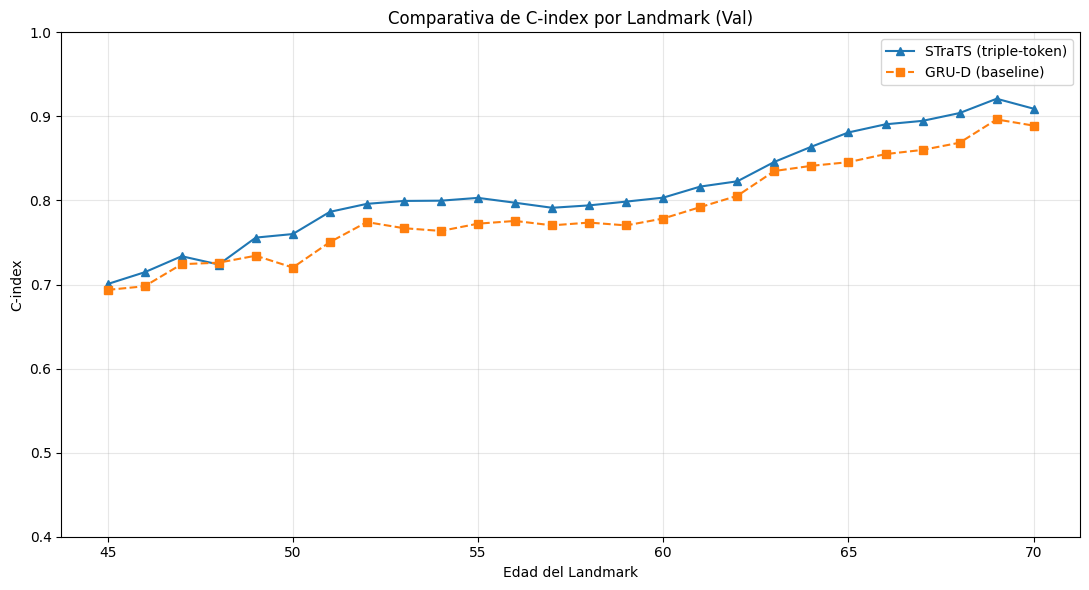


Mean C-index STraTS      : 0.8118


NameError: name 'mean_tr' is not defined

In [29]:
import json
import matplotlib.pyplot as plt

GRUD_METRICS_CANDIDATES_S = [
    Path.cwd().parent / 'results' / 'metrics' / 'grud.json',
    Path.cwd() / 'results' / 'metrics' / 'grud.json',
    DRIVE_BASE / 'results' / 'metrics' / 'grud.json' if DRIVE_BASE else None,
    DRIVE_BASE / 'tfm-mulcia-2025-1' / 'results' / 'metrics' / 'grud.json' if DRIVE_BASE else None,
]
GRUD_METRICS_CANDIDATES_S = [p for p in GRUD_METRICS_CANDIDATES_S if p is not None]
grud_json_path_s = next((p.resolve() for p in GRUD_METRICS_CANDIDATES_S if p.exists()), None)

if grud_json_path_s is None:
    print('No se encontro results/metrics/grud.json. Comparativa solo entre transformers.')
    grud_mean = np.nan
    old_ci_list = []
else:
    with open(grud_json_path_s, 'r', encoding='utf-8') as f:
        grud_data = json.load(f)
    print(f'Metricas de GRU-D cargadas desde: {grud_json_path_s}')
    val_landmarks = grud_data.get('c_index', {}).get('val', {}).get('landmarks', {})
    old_ci_list = [val_landmarks.get(str(lm), {}).get('c_index', np.nan) for lm in landmark_times_strats]
    grud_mean = float(grud_data.get('c_index', {}).get('val', {}).get('mean_c_index', np.nanmean(old_ci_list)))

x_st = landmark_times_strats[:len(ci_list_strats)]
# x_tr = landmark_times_strats[:len(ci_list_transformer)]
x_gr = landmark_times_strats[:len(old_ci_list)]

plt.figure(figsize=(11, 6))
plt.plot(x_st, ci_list_strats, marker='^', label='STraTS (triple-token)')
# plt.plot(x_tr, ci_list_transformer, marker='o', label='Transformer (visita-token)')
if old_ci_list:
    plt.plot(x_gr, old_ci_list, marker='s', linestyle='--', label='GRU-D (baseline)')
plt.title('Comparativa de C-index por Landmark (Val)')
plt.xlabel('Edad del Landmark')
plt.ylabel('C-index')
plt.grid(True, alpha=0.3)
plt.ylim(0.4, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

mean_st = float(np.nanmean(ci_list_strats)) if len(ci_list_strats) > 0 else np.nan
# mean_tr = float(np.nanmean(ci_list_transformer)) if len(ci_list_transformer) > 0 else np.nan

print()
print(f'Mean C-index STraTS      : {mean_st:.4f}')
print(f'Mean C-index Transformer : {mean_tr:.4f}')
print(f'Mean C-index GRU-D       : {grud_mean:.4f}')
print(f'Diferencia (STraTS - GRU-D)      : {mean_st - grud_mean:+.4f}')
print(f'Diferencia (STraTS - Transformer): {mean_st - mean_tr:+.4f}')
